# Reference pipeline

This notebook is the reference pipeline for inverse landscape genetics (ILG) with ILG Toolkit.
It relates pairwise Fst between 12 Mountain Pygmy-possum (*Burramys parvus*) sampling units in
the Victorian Alps to land cover. Three population-holdout folds each withhold four sampling
units. In each fold, an isolation-by-distance (IBD) model and a log-linear patch encoder trained with
the maximum-likelihood population effects (MLPE) loss, each with an MLPE calibration head,
predict the pairs that involve the withheld sampling units. The three landscape genetics models
with trained patch encoders, one per fold, form an ensemble, which summarizes the learned
resistance surface and the land-cover effects.

Genetic data: pairwise Fst kindly provided by Cesar Australia. Land cover: ESA WorldCover 2021
(CC BY 4.0).

In [1]:
import urllib.request
import zipfile
from itertools import combinations
from pathlib import Path
from tempfile import TemporaryDirectory

import coordax as cx
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import pandas as pd
import rioxarray
import xarray as xr
from ilg_toolkit import (
    Ensemble,
    fit_calibration_head,
    LandscapeGeneticsModel,
    load_model,
    MLPELoss,
    PairwiseObservations,
    RegionBatch,
    save_model,
    TargetSpec,
    train,
    TrainingConfig,
)
from ilg_toolkit.models import IBDModel, initialize_uniform_conductance, LogLinearConductance
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


# Effective resistance needs float64: enable x64 before creating any inputs.
jax.config.update("jax_enable_x64", True)
print(jax.devices())

[CudaDevice(id=0)]


## Land cover and sampling units

The example data hold the ESA WorldCover 2021 land-cover raster, the projected coordinates of
the sampling units and their pairwise Fst. Land-cover pixels of 8.36 m are averaged into cells
of about 84 m, giving the fraction of each class in each cell. The fractions of grassland,
permanent water and the remaining non-tree classes are the landscape features; tree cover is
the reference class. Each vertex of the conductance grid graph covers 8 × 8 cells, about 669 m.

In [2]:
DATA_URL = (
    "https://github.com/vboussange/ilg-toolkit/releases/download/"
    "example-data-v1/mountain-pygmy-possum.zip"
)
CACHE = Path("data") / "example-data-v1"
COARSENING = 10  # Averages 8.36 m land-cover pixels into cells of about 84 m.
PATCH_SIZE = 8  # Groups 8x8 cells into one vertex of about 669 m.
# ESA WorldCover classes merged into landscape features; tree cover is the reference.
FEATURE_CLASSES = {
    "grassland": [30],
    "permanent water": [80],
    "other": [20, 40, 50, 60, 90],  # Shrubland, cropland, built-up, bare, herbaceous wetland.
}

data = CACHE / "mountain-pygmy-possum"
if not data.is_dir():
    CACHE.mkdir(parents=True, exist_ok=True)
    archive, _ = urllib.request.urlretrieve(DATA_URL, CACHE / "mountain-pygmy-possum.zip")
    with zipfile.ZipFile(archive) as contents:
        contents.extractall(CACHE)
    Path(archive).unlink()
landcover = rioxarray.open_rasterio(data / "landcover.tif").squeeze("band", drop=True).load()
sites = pd.read_csv(data / "sites.csv", index_col="site")
fst = pd.read_csv(data / "fst.csv", index_col="site")

fractions = (
    xr.concat(
        [landcover.isin(codes) for codes in FEATURE_CLASSES.values()],
        dim=pd.Index(list(FEATURE_CLASSES), name="feature"),
    )
    .astype(np.float32)
    .coarsen(y=COARSENING, x=COARSENING, boundary="trim")
    .mean()
)
fractions = fractions.isel(
    y=slice(fractions.sizes["y"] // PATCH_SIZE * PATCH_SIZE),
    x=slice(fractions.sizes["x"] // PATCH_SIZE * PATCH_SIZE),
)
features = fractions.rename(y="row", x="column").transpose("row", "column", "feature")
region = RegionBatch.from_points(
    "victorian-alps",
    cx.from_xarray(features),
    sampling_unit_ids=tuple(sites.index),
    coordinates=sites[["x", "y"]].to_numpy(),
)
print(f"Land cover: {landcover.sizes['y']} x {landcover.sizes['x']} pixels")
print(f"Landscape features: {features.sizes['row']} x {features.sizes['column']} cells")
print(
    f"Conductance grid graph: {features.sizes['row'] // PATCH_SIZE} x "
    f"{features.sizes['column'] // PATCH_SIZE} vertices"
)

Land cover: 4596 x 3052 pixels
Landscape features: 456 x 304 cells
Conductance grid graph: 57 x 38 vertices


## Pairwise Fst and population-holdout folds

The target is pairwise Fst, on the model scale of its odds Fst / (1 − Fst), the linearized Fst.
The 12 sampling units are assigned at random to three folds of four. In each fold, two of the
eight remaining sampling units are drawn at random as validation units, and the other six are
training units. Training pairs join two training units, validation pairs join a validation unit
to another sampling unit outside the fold, and test pairs involve at least one sampling unit of
the fold. Calibration pairs, all pairs among the eight sampling units outside the fold, fit the
MLPE calibration heads.

In [3]:
observations = PairwiseObservations(
    tuple(fst.index),
    fst.to_numpy(),
    target=TargetSpec("pairwise Fst", units="proportion", transform="odds"),
)
folds = np.array_split(np.random.default_rng(0).permutation(sites.index), 3)
rng = np.random.default_rng(1)
validation_units, training_sets, validation_sets, calibration_sets, test_sets = [], [], [], [], []
for held_out in folds:
    calibration_ids = sites.index.difference(held_out)
    validation_ids = rng.choice(calibration_ids, 2, replace=False)
    training_ids = calibration_ids.difference(validation_ids)
    calibration = observations.select_pairs(list(combinations(calibration_ids, 2)))
    validation_units.append(validation_ids)
    training_sets.append(observations.select_pairs(list(combinations(training_ids, 2))))
    validation_sets.append(
        calibration.select_pairs(
            [pair for pair in calibration.observed_pairs if set(pair) & set(validation_ids)]
        )
    )
    calibration_sets.append(calibration)
    test_sets.append(
        observations.select_pairs(
            [pair for pair in observations.observed_pairs if set(pair) & set(held_out)]
        )
    )

fst.round(3)

,Basalt Hill,Bundara Scree,Higginbotham East,Higginbotham West,Little Higginbotham,Mt Bogong,Mt Loch East,Mt Loch North,Mt McKay,Pretty Valley West,Spargo,Timms Spur
site,,,,,,,,,,,,
Basalt Hill,0.000,0.176,0.186,0.187,0.189,0.216,0.169,0.173,0.169,0.186,0.195,0.204
Bundara Scree,0.176,0.000,0.068,0.067,0.065,0.104,0.047,0.046,0.054,0.059,0.046,0.111
Higginbotham East,0.186,0.068,0.000,0.009,0.044,0.120,0.043,0.046,0.070,0.075,0.028,0.118
Higginbotham West,0.187,0.067,0.009,0.000,0.043,0.118,0.043,0.045,0.066,0.073,0.029,0.115
Little Higginbotham,0.189,0.065,0.044,0.043,0.000,0.119,0.041,0.042,0.068,0.071,0.021,0.116
Mt Bogong,0.216,0.104,0.120,0.118,0.119,0.000,0.100,0.099,0.088,0.102,0.095,0.043
Mt Loch East,0.169,0.047,0.043,0.043,0.041,0.100,0.000,0.010,0.052,0.055,0.014,0.099
Mt Loch North,0.173,0.046,0.046,0.045,0.042,0.099,0.010,0.000,0.052,0.054,0.016,0.098
Mt McKay,0.169,0.054,0.070,0.066,0.068,0.088,0.052,0.052,0.000,0.046,0.049,0.092


In [4]:
pd.DataFrame(
    {
        "held-out sampling units": [", ".join(sorted(held_out)) for held_out in folds],
        "validation units": [", ".join(sorted(ids)) for ids in validation_units],
        "training pairs": [len(pairs.observed_pairs) for pairs in training_sets],
        "validation pairs": [len(pairs.observed_pairs) for pairs in validation_sets],
        "calibration pairs": [len(pairs.observed_pairs) for pairs in calibration_sets],
        "test pairs": [len(pairs.observed_pairs) for pairs in test_sets],
    },
    index=pd.RangeIndex(1, len(folds) + 1, name="fold"),
)

,held-out sampling units,validation units,training pairs,validation pairs,calibration pairs,test pairs
fold,,,,,,
1,"Higginbotham East, Little Higginbotham, Mt Loc...","Mt Bogong, Mt Loch East",15,13,28,38
2,"Basalt Hill, Higginbotham West, Mt Bogong, Tim...","Bundara Scree, Pretty Valley West",15,13,28,38
3,"Bundara Scree, Mt Loch East, Mt McKay, Spargo","Mt Loch North, Timms Spur",15,13,28,38


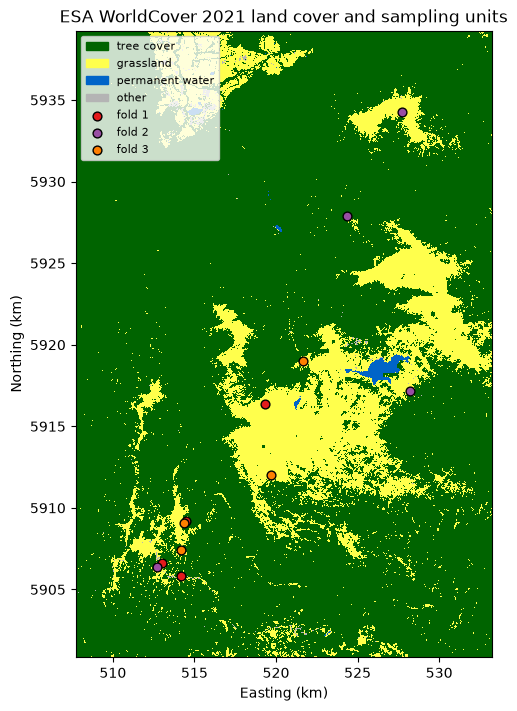

In [5]:
classes = xr.zeros_like(landcover, dtype=np.uint8)
for index, codes in enumerate(FEATURE_CLASSES.values(), start=1):
    classes = classes.where(~landcover.isin(codes), index)
CLASS_COLORS = ["#006400", "#ffff4c", "#0064c8", "#b4b4b4"]
CLASS_NAMES = ["tree cover", *FEATURE_CLASSES]
FOLD_COLORS = ["#e41a1c", "#984ea3", "#ff7f00"]


def kilometers(axis):
    axis.xaxis.set_major_formatter(lambda value, _: f"{value / 1e3:.0f}")
    axis.yaxis.set_major_formatter(lambda value, _: f"{value / 1e3:.0f}")
    axis.set(xlabel="Easting (km)", ylabel="Northing (km)", aspect="equal")


figure, axis = plt.subplots(figsize=(5.5, 7), layout="constrained")
classes.plot.imshow(
    ax=axis, cmap=ListedColormap(CLASS_COLORS), vmin=-0.5, vmax=3.5, add_colorbar=False
)
for fold, (held_out, color) in enumerate(zip(folds, FOLD_COLORS, strict=True), start=1):
    axis.scatter(
        *sites.loc[held_out, ["x", "y"]].T.to_numpy(),
        s=40,
        c=color,
        edgecolors="black",
        label=f"fold {fold}",
    )
handles = [Patch(color=color, label=name) for color, name in zip(CLASS_COLORS, CLASS_NAMES)]
axis.legend(handles=[*handles, *axis.get_legend_handles_labels()[0]], loc="upper left", fontsize=8)
axis.set_title("ESA WorldCover 2021 land cover and sampling units")
kilometers(axis)
plt.show()

## IBD model

The IBD model's ecological distance is an affine function of the straight-line distance between
the sampling units' vertices, on the same vertices as the patch encoder. Each fold's IBD model
keeps its initial slope and intercept, and `fit_calibration_head` fits its MLPE calibration head
on the calibration pairs.

In [6]:
loss = MLPELoss()
ibd_models = []
for calibration in calibration_sets:
    ibd = IBDModel(patch_size=PATCH_SIZE)
    calibration_head = fit_calibration_head(region, calibration, ibd, loss=loss)
    ibd_models.append(LandscapeGeneticsModel(ibd, calibration_head, region.feature_names))

pd.DataFrame(
    [
        {
            "MLPE slope": mlpe_calibration.slope,
            "population variance": mlpe_calibration.unit_variance,
            "residual variance": mlpe_calibration.residual_variance,
            "log likelihood": mlpe_calibration.ml_log_likelihood,
        }
        for mlpe_calibration in (
            model.calibration_head.for_region(region.name) for model in ibd_models
        )
    ],
    index=pd.RangeIndex(1, len(folds) + 1, name="fold"),
)

,MLPE slope,population variance,residual variance,log likelihood
fold,,,,
1,0.025166,0.002693,0.000233,59.935815
2,0.012491,0.000077,0.000013,102.654083
3,0.030275,0.002447,0.000226,60.643914


## Log-linear patch encoder

The log-linear patch encoder maps the patch means $x_k$ of the three land-cover fractions to the
conductance $C_k = \min\{e^{\beta^\top x_k + \beta_0} + 10^{-2}, 10^3\}$ of vertex $k$. In each
fold, the patch encoder is initialized at the best uniform conductance and trained on the
training pairs with the MLPE loss and AdamW (learning rate $10^{-2}$, weight decay $10^{-4}$)
for 1,000 updates. Training evaluates the model every 10 updates and selects the update with
the lowest validation loss. The selected patch encoder, frozen, receives an MLPE calibration
head fitted on the calibration pairs.

In [7]:
config = TrainingConfig(
    loss=loss, optimizer=optax.adamw(1e-2, weight_decay=1e-4), steps=1000, eval_every=10
)
states, patch_models = [], []
for training, validation, calibration in zip(
    training_sets, validation_sets, calibration_sets, strict=True
):
    distance_model = initialize_uniform_conductance(
        LogLinearConductance(3, patch_size=PATCH_SIZE), region, training, loss
    )
    state = train(
        region,
        training,
        distance_model=distance_model,
        config=config,
        validation=(region, validation),
    )
    selected = state.selected_model.distance_model
    calibration_head = fit_calibration_head(region, calibration, selected, loss=loss)
    states.append(state)
    patch_models.append(LandscapeGeneticsModel(selected, calibration_head, region.feature_names))

pd.DataFrame(
    {
        "selected update": [state.selected_step for state in states],
        "initial validation loss": [state.history[0].validation_loss for state in states],
        "selected validation loss": [state.selected_loss for state in states],
    },
    index=pd.RangeIndex(1, len(folds) + 1, name="fold"),
)

,selected update,initial validation loss,selected validation loss
fold,,,
1,170,-1.393227,-1.574191
2,50,-2.958546,-3.039169
3,200,-1.408699,-1.651802


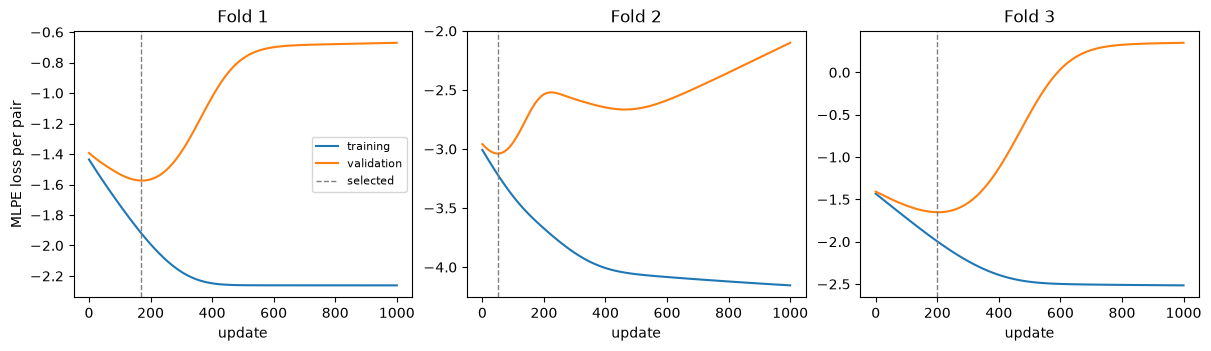

In [8]:
figure, axes = plt.subplots(1, 3, figsize=(12, 3.4), layout="constrained")
for fold, (axis, state) in enumerate(zip(axes, states, strict=True), start=1):
    steps = [record.step for record in state.history]
    axis.plot(steps, [record.training_loss for record in state.history], label="training")
    axis.plot(steps, [record.validation_loss for record in state.history], label="validation")
    axis.axvline(state.selected_step, color="gray", linestyle="--", linewidth=1, label="selected")
    axis.set(title=f"Fold {fold}", xlabel="update")
axes[0].set_ylabel("MLPE loss per pair")
axes[0].legend(fontsize=8)
plt.show()

## Population-holdout evaluation

Each model gives marginal predictions for the test pairs of its fold on the original Fst scale.
Pearson's $r$, predictive $R^2 = 1 - \sum (y - \hat y)^2 / \sum (y - \bar y)^2$ and the root
mean squared error (RMSE) compare the predictions $\hat y$ with the observed Fst $y$ in each
fold.

In [9]:
rows, predictions = [], []
for fold, test in enumerate(test_sets, start=1):
    observed = np.asarray(test.observed_values)
    for name, model in (
        ("IBD model", ibd_models[fold - 1]),
        ("log-linear patch encoder", patch_models[fold - 1]),
    ):
        predicted = np.asarray(model.predict(region, test.observed_pairs).values)
        predictions.append((fold, name, observed, predicted))
        rows.append(
            {
                "fold": fold,
                "model": name,
                "Pearson's r": np.corrcoef(observed, predicted)[0, 1],
                "predictive R²": 1
                - np.sum((observed - predicted) ** 2) / np.sum((observed - observed.mean()) ** 2),
                "RMSE": np.sqrt(np.mean((observed - predicted) ** 2)),
            }
        )
metrics = pd.DataFrame(rows)
metrics.pivot(index="fold", columns="model").round(3)

Pearson's r                          predictive R²  \
model   IBD model log-linear patch encoder     IBD model   
fold                                                       
1           0.696                    0.723         0.228   
2           0.300                    0.327        -0.587   
3           0.571                    0.602        -0.079   

                                    RMSE                           
model log-linear patch encoder IBD model log-linear patch encoder  
fold                                                               
1                        0.333     0.042                    0.039  
2                       -0.746     0.067                    0.070  
3                       -0.151     0.046                    0.048

In [10]:
metrics.drop(columns="fold").groupby("model").agg(["mean", "std"]).round(3)

Pearson's r        predictive R²          RMSE       
                                mean    std          mean    std   mean    std
model                                                                         
IBD model                      0.522  0.203        -0.146  0.412  0.052  0.013
log-linear patch encoder       0.550  0.203        -0.188  0.541  0.052  0.016

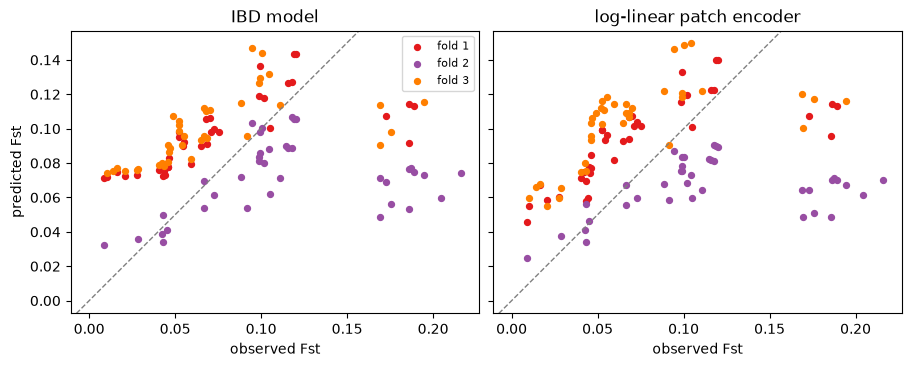

In [11]:
figure, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharex=True, sharey=True, layout="constrained")
for axis, name in zip(axes, ("IBD model", "log-linear patch encoder"), strict=True):
    for fold, model_name, observed, predicted in predictions:
        if model_name == name:
            axis.scatter(
                observed, predicted, s=18, color=FOLD_COLORS[fold - 1], label=f"fold {fold}"
            )
    axis.axline((0, 0), slope=1, color="gray", linestyle="--", linewidth=1)
    axis.set(title=name, xlabel="observed Fst", aspect="equal")
axes[0].set_ylabel("predicted Fst")
axes[0].legend(fontsize=8)
plt.show()

## Ensemble and learned resistance surface

The three landscape genetics models with trained patch encoders, one per population-holdout
fold, form an ensemble, whose genetic prediction averages the members on the original Fst
scale. For each member, the $\log_{10}$ resistance relative to tree cover at vertex $k$ is
$\log_{10}(Q_k / Q_\mathrm{tree})$, where $Q_k = 1/C_k$ is the local resistance and
$Q_\mathrm{tree}$ the local resistance of a vertex covered by tree cover. At each vertex, its
median and interquartile range (IQR) across the members summarize the learned resistance
surface.

In [12]:
ensemble = Ensemble(patch_models)
prediction = ensemble.predict(region, observations.observed_pairs)
pd.DataFrame(
    {
        "observed Fst": np.asarray(observations.observed_values),
        "ensemble mean": prediction.mean.values,
    }
    | {
        f"member {index}": member.values for index, member in enumerate(prediction.members, start=1)
    },
    index=pd.MultiIndex.from_tuples(prediction.mean.pairs),
).head().round(3)

observed Fst  ensemble mean  member 1  \
Basalt Hill Bundara Scree               0.176          0.089     0.098   
            Higginbotham East           0.186          0.101     0.114   
            Higginbotham West           0.187          0.103     0.116   
            Little Higginbotham         0.189          0.100     0.113   
            Mt Bogong                   0.216          0.108     0.120   

                                 member 2  member 3  
Basalt Hill Bundara Scree           0.051     0.118  
            Higginbotham East       0.070     0.119  
            Higginbotham West       0.071     0.121  
            Little Higginbotham     0.070     0.115  
            Mt Bogong               0.070     0.133

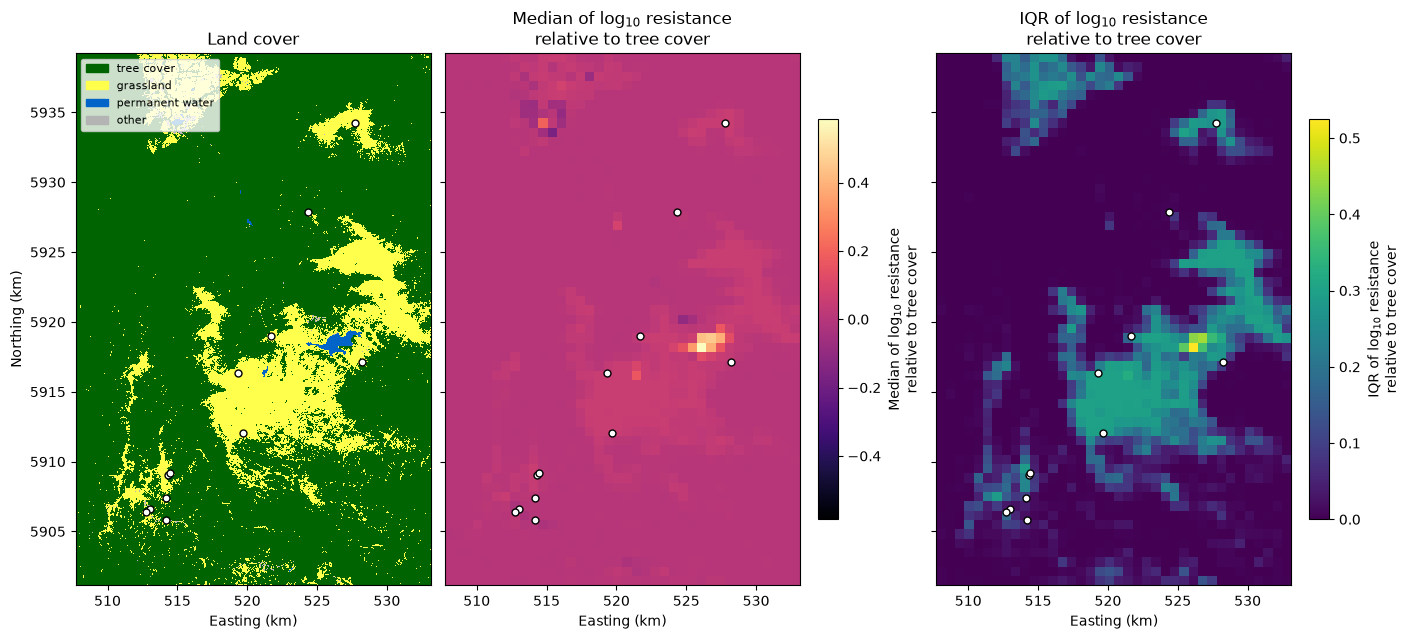

In [13]:
tree_cover = jnp.zeros(len(region.feature_names))  # Land-cover fractions of a tree-cover vertex.
relative_log_resistance = xr.concat(
    [
        np.log10(
            float(member.distance_model.conductance(tree_cover, 0))
            / member.distance_model.conductance_surface(region).to_xarray()
        )
        for member in ensemble.members
    ],
    dim="member",
)
median = relative_log_resistance.median("member")
quartiles = relative_log_resistance.quantile([0.25, 0.75], "member")
iqr = quartiles.sel(quantile=0.75) - quartiles.sel(quantile=0.25)

figure, axes = plt.subplots(1, 3, figsize=(14, 6.4), sharex=True, sharey=True, layout="constrained")
classes.plot.imshow(
    ax=axes[0], cmap=ListedColormap(CLASS_COLORS), vmin=-0.5, vmax=3.5, add_colorbar=False
)
axes[0].legend(
    handles=[Patch(color=color, label=name) for color, name in zip(CLASS_COLORS, CLASS_NAMES)],
    loc="upper left",
    fontsize=8,
)
axes[0].set_title("Land cover")
for axis, surface, title, cmap in (
    (axes[1], median, "Median of log$_{10}$ resistance\nrelative to tree cover", "magma"),
    (axes[2], iqr, "IQR of log$_{10}$ resistance\nrelative to tree cover", "viridis"),
):
    image = surface.plot.imshow(
        ax=axis, x="column", y="row", cmap=cmap, cbar_kwargs={"shrink": 0.7, "label": title}
    )
    axis.set_title(title)
    axis.axis(image.get_extent())
for axis in axes:
    axis.scatter(sites["x"], sites["y"], s=25, c="white", edgecolors="black")
    kilometers(axis)
for axis in axes[1:]:
    axis.set_ylabel("")
plt.show()

## Land-cover effects

`feature_effects` returns each member's log-linear coefficients by feature name. The features
are land-cover fractions with tree cover omitted, so each effect is the log-conductance
difference between a patch covered by that class and a patch covered by tree cover. A negative
effect marks a class with a lower conductance, and a higher resistance, than tree cover.

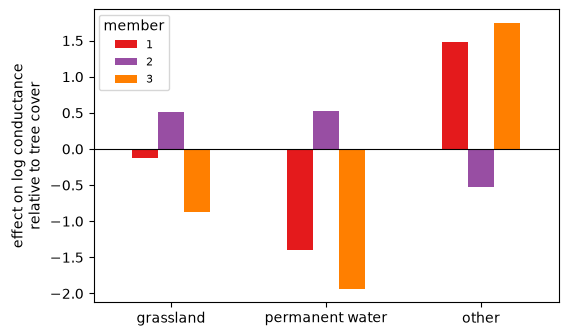

,grassland,permanent water,other
member,,,
1,-0.121,-1.396,1.476
2,0.507,0.529,-0.525
3,-0.879,-1.933,1.749


In [14]:
effects = pd.DataFrame(
    [
        {
            name: value
            for name, (value,) in member.distance_model.feature_effects(
                region.feature_names
            ).items()
        }
        for member in ensemble.members
    ],
    index=pd.RangeIndex(1, len(folds) + 1, name="member"),
)
axis = effects.T.plot.bar(color=FOLD_COLORS, figsize=(6, 3.8), rot=0)
axis.axhline(0, color="black", linewidth=0.8)
axis.set(ylabel="effect on log conductance\nrelative to tree cover", xlabel="")
axis.legend(title="member", fontsize=8)
plt.show()
effects.round(3)

## Saving and reloading the members

`save_model` writes each member to one file. `load_model` reads it into a log-linear patch
encoder built with the same settings, and the reloaded members form the same ensemble.

In [15]:
with TemporaryDirectory() as directory:
    paths = [Path(directory) / f"member-{index}.eqx" for index in range(1, len(folds) + 1)]
    for path, member in zip(paths, ensemble.members, strict=True):
        save_model(path, member)
    template = LogLinearConductance(3, patch_size=PATCH_SIZE)
    reloaded = Ensemble([load_model(path, distance_model=template) for path in paths])

print(
    "Members equal:",
    all(
        eqx.tree_equal(member, original)
        for member, original in zip(reloaded.members, ensemble.members, strict=True)
    ),
)
reloaded_prediction = reloaded.predict(region, observations.observed_pairs)
print(
    "Predictions equal:",
    np.allclose(reloaded_prediction.mean.values, prediction.mean.values, rtol=1e-6, atol=0),
)

Members equal: True
Predictions equal: True
